<a href="https://colab.research.google.com/github/Ale-yo/NeuralNetwork-Failure-Propagation/blob/main/Failure_Propagation_NeuralNetworks_Alessia_Cecchini.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **DAMAGE PROPAGATION IN A U-BOLT (FKPP model)**
## **Assignment 2: Damage Propagation and Neural Networks**

*Alessia Cecchini* \
*Model Order Reduction Techniques* \
MSc in Mechanical Engineering, Politecnico di Milano

The code below is only partially showing the satisfactory results obtained with a passionate reasoning over the implementation strategies, leveraging the knowledge and tools acquired during the course.

### Fisher-Kolmogorov-Petrovsky-Piskunov model

The damage propagation in a U-bolt is defined in space and time as

$$u(\mathbf{x}, t) : \Omega \times [0, T] \to [0, 1]$$

as the solution to

$$\begin{cases}
\dfrac{\partial u}{\partial t} - D \Delta u = r u (1 - u) & \text{in } \Omega \times (0, T), \\[1.2ex]
\nabla u \cdot \mathbf{n} = 0 & \text{on } \partial \Omega \times (0, T), \\[1.2ex]
u(\cdot, 0) = g_{\delta} & \text{in } \overline{\Omega},
\end{cases}$$

where $D > 0$ and $r > 0$ are the diffusion and reaction coefficients, respectively, whereas $\delta$ describes the location of the initial damage. Specifically,

$$g_{\delta}(x, y) := \begin{cases}
1 & \text{if } |x - \delta| < 0.1 \text{ and } y \ge 4, \\
0 & \text{otherwise.}
\end{cases}$$

For the sake of our analysis, we parametrize the model coefficients as

$$D = 10^{\mu_1}, \quad r = 10^{\mu_2 + 2}, \quad \delta = \mu_3 + 1,$$

where $\boldsymbol{\mu} = [\mu_1, \mu_2, \mu_3]^T \in [0, 1]^3$. The final time is set to $T = 0.02$.

# **LOAD DATA FROM DRIVE**

In [ ]:
try:
    import gdown
except ImportError:
    !pip install gdown
    import gdown

import os
file_ids = {
    'phi_PODNN_state_dict.pth': '1y037mAsyz3Mh1EZ2h5lznfEPP1172bah',
    'autoencoder_state_dict.pth': '1uuStmZ6HB3l76cAg2tz_RF6MtxGb7GDE',
    'dlrom_phi_state_dict.pth': '1K00nuaXwVkk-4Fj6BCbF1r5w4iWe1D33',
    'saved_data.npz': '167jRPMC_zNTx9K2-1AJ6HDC7crE7egRN',
    'damage_measurements.npy': '1dfH99xyrK8oaX6OG3-BaRsBqxoGf-0vE'
}

# Download each file
for file_name, file_id in file_ids.items():
    if 'YOUR_' in file_id: # Check if the ID is still a placeholder
        print(f"Skipping download for '{file_name}' as the file ID is a placeholder. Please update it in the `file_ids` dictionary.")
        continue

    output_path = f'/content/{file_name}'
    try:
        gdown.download(id=file_id, output=output_path, quiet=False)
        print(f"Downloaded '{file_name}' to '{output_path}'.")
    except Exception as e:
        print(f"Error downloading '{file_name}' with ID '{file_id}': {e}")
        print(f"Please ensure the file ID is correct and the file is publicly accessible or 'Anyone with the link' can view it.")

print("Finished attempting to download all specified files.")

Downloading...
From: https://drive.google.com/uc?id=1y037mAsyz3Mh1EZ2h5lznfEPP1172bah
To: /content/phi_PODNN_state_dict.pth
100%|██████████| 164k/164k [00:00<00:00, 3.20MB/s]


Downloaded 'phi_PODNN_state_dict.pth' to '/content/phi_PODNN_state_dict.pth'.


Downloading...
From (original): https://drive.google.com/uc?id=1uuStmZ6HB3l76cAg2tz_RF6MtxGb7GDE
From (redirected): https://drive.google.com/uc?id=1uuStmZ6HB3l76cAg2tz_RF6MtxGb7GDE&confirm=t&uuid=b1bf6de0-0d86-47b5-bb08-7b9c6f5e8c78
To: /content/autoencoder_state_dict.pth
100%|██████████| 44.1M/44.1M [00:00<00:00, 82.1MB/s]


Downloaded 'autoencoder_state_dict.pth' to '/content/autoencoder_state_dict.pth'.


Downloading...
From: https://drive.google.com/uc?id=1K00nuaXwVkk-4Fj6BCbF1r5w4iWe1D33
To: /content/dlrom_phi_state_dict.pth
100%|██████████| 15.2k/15.2k [00:00<00:00, 40.3MB/s]


Downloaded 'dlrom_phi_state_dict.pth' to '/content/dlrom_phi_state_dict.pth'.


Downloading...
From (original): https://drive.google.com/uc?id=167jRPMC_zNTx9K2-1AJ6HDC7crE7egRN
From (redirected): https://drive.google.com/uc?id=167jRPMC_zNTx9K2-1AJ6HDC7crE7egRN&confirm=t&uuid=fa8c71b7-5e6a-4e36-a863-eafe663241c8
To: /content/saved_data.npz
100%|██████████| 109M/109M [00:01<00:00, 76.9MB/s]


Downloaded 'saved_data.npz' to '/content/saved_data.npz'.


Downloading...
From: https://drive.google.com/uc?id=1dfH99xyrK8oaX6OG3-BaRsBqxoGf-0vE
To: /content/damage_measurements.npy
100%|██████████| 292/292 [00:00<00:00, 1.11MB/s]

Downloaded 'damage_measurements.npy' to '/content/damage_measurements.npy'.
Finished attempting to download all specified files.


#

In [ ]:
try:
    from dlroms import*
except:
    !pip install --no-deps git+https://github.com/NicolaRFranco/dlroms.git
    from dlroms import*
import numpy as np
import matplotlib.pyplot as plt
import gdown
clc()

In [ ]:
import numpy as np
import torch

# You can use the full sharing URL, and the code will attempt to extract the ID.
GOOGLE_DRIVE_LINK_OR_ID = 'https://colab.research.google.com/drive/1pbK3Up6i4mfxoc9GyxOncTZyJoLaXbAi?usp=sharing'

# Extract just the ID if a full link is provided
if 'drive.google.com/file/d/' in GOOGLE_DRIVE_LINK_OR_ID:
    GOOGLE_DRIVE_FILE_ID = GOOGLE_DRIVE_LINK_OR_ID.split('/d/')[1].split('/view')[0]
else:
    GOOGLE_DRIVE_FILE_ID = GOOGLE_DRIVE_LINK_OR_ID

# --- Load Numerical Data ---
# This assumes the files have been copied to /content/ by the previous cell.


if os.path.exists('/content/saved_data.npz'):
    loaded_np_data = np.load('/content/saved_data.npz')
    print("Loading numerical data from 'saved_data.npz'...")
    global mu, u, mut, zsindy # Declare global if these variables are meant to be updated globally
    # dv is now guaranteed to be imported from the dlroms cell
    mu = dv.tensor(loaded_np_data['mu'])
    u = dv.tensor(loaded_np_data['u'])
    mut = dv.tensor(loaded_np_data['mut'])
    zsindy = dv.tensor(loaded_np_data['zsindy'])
    print("Numerical data (mu, u, mut, zsindy) loaded.")
else:
    print("Skipping numerical data loading: 'saved_data.npz' not found. These will be generated later if not present.")

if os.path.exists('/content/damage_measurements.npy'):
    global damage_measurements
    damage_measurements = np.load('/content/damage_measurements.npy')
    print("'damage_measurements.npy' loaded.")
else:
    print("Skipping 'damage_measurements.npy' loading: file not found. This will be downloaded later if not present.")

# u-bolt.npz is typically loaded by a dedicated cell later, or implicitly by mu/u if they are saved in saved_data.npz.
# No explicit loading of u-bolt.npz here to avoid redundancy and potential overwrites if mu/u are from saved_data.npz.
print("Finished loading all available numerical data.")

Loading numerical data from 'saved_data.npz'...
Numerical data (mu, u, mut, zsindy) loaded.
'damage_measurements.npy' loaded.
Finished loading all available numerical data.


# **FOM DATASET (given by the professor)**


### Mesh construction and data download

In [ ]:
# Mesh definition
points = [np.array([0.0, 0.0])]
def step(z):
  points.append(points[-1] + [z.real, z.imag])
def arch(r, thetas, knots = 30):
  rho = np.abs(r)
  center = points[-1] + [r.real, r.imag]
  th = np.linspace(*thetas, knots)[1:]
  shift = rho*np.exp(1j*th)
  vals = np.stack([center[0] + shift.real, center[1]+shift.imag], axis = 1)
  for v in vals:
    points.append(v)

step(3j)
arch(2, thetas = (np.pi, 0))
step(-3j)
step(-1)
step(3j)
arch(-1, thetas = (0, np.pi))
step(-3j)
step(-1)

points = np.stack(points)

domain = fe.polygon(points)
mesh = fe.mesh(domain, stepsize = 0.05)
Vh = fe.space(mesh, 'CG', 1)
clc()

In [ ]:
nh = Vh.dim() # size of mesh
nh

6636

In [ ]:
# Data download
gdown.download(id = "1ehojde4rL-8-zoyiKikes3e76CpPvJzC", quiet = False, output = "u-bolt.npz")
clc()

data = np.load("u-bolt.npz")
mu, u = dv.tensor(data['mu'], data['u'])                                        # transform both in tensor form

mu.shape, u.shape                                                               # mu = (num_simulations, num_parameters) | u = (num_simulations, num_timesnapshots, dimension_mesh)

(torch.Size([100, 3]), torch.Size([100, 41, 6636]))

### Animation plot


In [ ]:
# Damage plot with modified colors

from matplotlib.colors import ListedColormap
import matplotlib as mpl
jet = mpl.colormaps['jet']
jet_colors = jet(np.linspace(0, 1, 256))
def modify_jet_to_gray(jet_colors):
    new_colors = jet_colors.copy()
    gray_vals = np.linspace(0.3, 0.7, 85)
    for i in range(85):
        new_colors[i, 0:3] = gray_vals[i]
    return ListedColormap(new_colors)
gray_jet = modify_jet_to_gray(jet_colors)

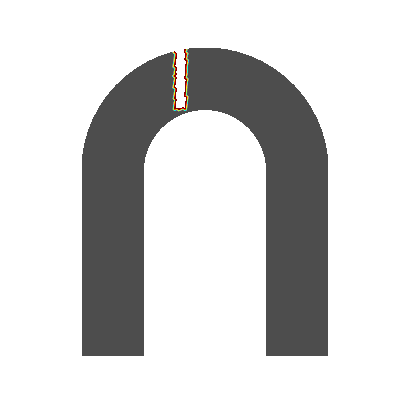

In [ ]:
# Usage example
fe.animate(u[0], Vh, cmap = gray_jet) # 1st simulation in the dataset - change index of u to see other simulations (range 0 - 99 as we have 100 simulations)

# **1) POD-NN or DL-ROM?**


The first point requires to select a proper ROM for the analysis of the damage propagation in a U-bolt described by the Fisher-Kolmogorov-Petrovsky-Piskunov equation.
At the beginning, as also usually implemented in the laboratories, can proceed by verifying whether the Proper Orthogonal Decomposition, combined with Neural Networks, is feasible.

## POD-NN implementation





### Arrangement of data

In [ ]:
## Dimensions of u and mu
ndata, nt, nh = u.shape                                                         # ndata = 100, nt = 41, nh = 6636
ndata, p = mu.shape                                                             # ndata = 100, p = 3 (num parameters)


print(f"Number of samples = {ndata}")
print(f"Number of time steps = {nt}")
print(f"Number of degrees of freedom = {nh}")
print(f"Number of parameters = {p}")
print(f"Dimension of u is {u.shape}")
print(f"Dimension of mu is {mu.shape}")

Number of samples = 100
Number of time steps = 41
Number of degrees of freedom = 6636
Number of parameters = 3
Dimension of u is torch.Size([100, 41, 6636])
Dimension of mu is torch.Size([100, 3])


In [ ]:
## Time data (by the professor)
dt = 5e-4                                                                       # time steps
T = (nt-1)*dt                                                                   # final time (given by text)

In [ ]:
## Adjust the dimension of u and mu

# u
u = u.reshape(-1, nh)

# mu + time introduced as parameter
t = dv.tensor(np.linspace(0, T, nt))                                            # nt = number of time steps in (start - end) interval

mut = dv.zeros(ndata, nt, p+1)                                                  # create null tensor of desidered shape  (100 x 41 x 4)
for i in range(ndata):                                                          # add values to mut
  mut[i, :, :p] = mu[i]                                                         # fix a simulation --> the parameter is constant
  mut[i, :, p] = t
mut = mut.reshape(-1, p+1)                                                      # (ndata*nt x p) = (100*41 x 4)

print(f'The dimension of mu considering time as parameter is: {mut.shape}')
print(f'The dimension of mu considering time as parameter is: {u.shape}')

The dimension of mu considering time as parameter is: torch.Size([4100, 4])
The dimension of mu considering time as parameter is: torch.Size([4100, 6636])


### SVD and POD Basis

The first fundamental step to assemble POD basis consists in considering a snapshots training set (of size $75$, as given by the text) taken from Full Order Model solution, apply Singular Value Decomposition to it, and plot the decay of the singular values.

The POD solution can be implemented as long as the singular values decay is sharp, as the number of the relevant singular values (i.e. those with higher value, which implies storing an higher amount of energy) would correspond to the dimension of the latent space, obtained by means of the POD basis.


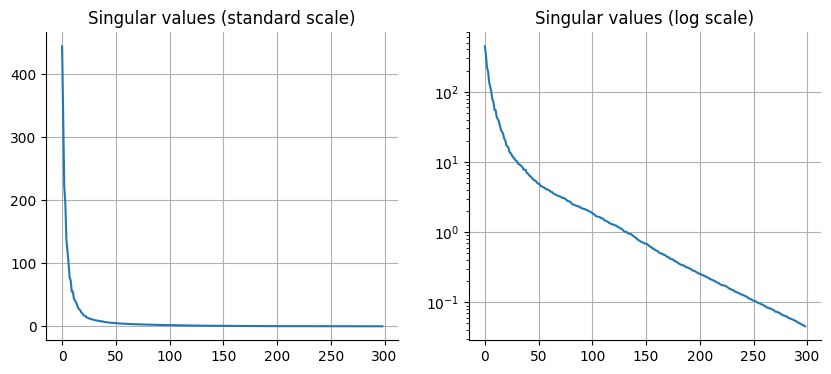

Utrain.T = torch.Size([6636, 3075])
X = (6636, 3075)
s = (3075,)


In [ ]:
## Check if POD-NN is feasible

# Split data into traininig - testing
numtrain = 75                                                                   # given by text
numtest = 25                                                                    # given by text
ntrain = numtrain*nt                                                            # multiplied by nt as we have reshaped u
ntest = numtest*nt                                                              # multiplied by nt as we have reshaped u
Utrain = u[:ntrain]
Utest = u[ntrain:]

## Perform SVD over training matrix
from scipy.linalg import svd
import matplotlib.pyplot as plt

X, s, _ = svd(Utrain.T.cpu().numpy(), full_matrices = False)                    # transpose of Utrain --> want the snapshots on the columns!

## Plot the singular values
# Plot in decimal scale
plt.figure(figsize=(10, 4))
plt.subplot(1,2,1)
plt.plot(s[1:300])                                                              # exclude the first (as typically very high) and consider up to 300 - exclude those after as non significant
plt.title('Singular values (standard scale)')
plt.grid(True)
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Plot in logarithmic scale
plt.subplot(1,2,2)
plt.plot(s[1:300])
plt.yscale('log')
plt.title('Singular values (log scale)')
plt.grid(True)
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.show()
print(f"Utrain.T = {Utrain.T.shape}")
print(f"X = {X.shape}")
print(f"s = {s.shape}")

Looking at the singular values decay, a feasible dimension of the reduced basis $V_n$ is $n = 50$. On a first attempt, this is considered as good since the starting dimension (the one of the Full Order Model) is $N_h = 6636$, with respect to which the chosen dimension seems small.

In [ ]:
## POD Basis
n = 50
Vn = X[:, :n]
print(f'The shape of the POD basis Vn is: {Vn.shape}')

The shape of the POD basis Vn is: (6636, 50)


### Neural Network implementation $ϕ(\mu_i):\mathbb{R}^p→\mathbb{R}^{n} ≈ c_i $

---



At this point, the POD architecture has been implemented. The missing part is the Neural Network.

The development of it comes by the necessity of replacing the Galerkin RB projection, to obtain something cheaper in terms of computational burden and of time.
Indeed, $Φ(\mu_i)$ should replace the computation of $u_n(\mu_i)$ as new parameters come in. For such a reason, the Neural Network is implemented as the one that should better approximate $u_n$ or, equivalently, $c_i = u_h(\mu_i)V_n$.

In [ ]:
## Tranform mut, u, Vn into tensors
mut, u, Vn = dv.tensor(mut, u, Vn)

/usr/local/lib/python3.12/dist-packages/dlroms/cores.py:58: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return (*[ttensor(array, dtype = self.dtype, device = self.device) for array in arrays],)


In [ ]:
## Define the optimal approximation of u_mu --> c is u in the latent space!
c = u @ Vn                                                                      # size: (ndata*nt x nh) x (nh x n) -> (ndata*nt x n)
u.shape, Vn.shape, c.shape, mut.shape, ntrain

(torch.Size([4100, 6636]),
 torch.Size([6636, 50]),
 torch.Size([4100, 50]),
 torch.Size([4100, 4]),
 3075)

In [ ]:
## Dimension of mu considering the addition of time
pt = mut.shape[1]

In [ ]:
mut.shape, mut[ntrain:].shape

(torch.Size([4100, 4]), torch.Size([1025, 4]))

In [ ]:
# ## Tools to move to the GPU
u.cuda()
mut.cuda()
Vn.cuda()
c.cuda()

tensor([[-4.0843e+00, -3.5008e+00, -1.3555e+00,  ...,  5.6700e-02,
          2.8085e-01,  1.0039e-01],
        [-4.4544e+00, -3.7496e+00, -1.4636e+00,  ..., -6.4957e-02,
          5.0400e-02, -9.4469e-02],
        [-4.9944e+00, -4.1241e+00, -1.6134e+00,  ..., -8.8221e-03,
         -2.6550e-02, -4.5356e-02],
        ...,
        [-3.4382e+01, -1.6034e+00, -6.2941e+00,  ..., -1.3708e-01,
         -4.2643e-02,  6.2657e-02],
        [-3.5222e+01, -9.1767e-01, -5.9695e+00,  ..., -1.4824e-01,
         -6.3480e-02,  6.5412e-02],
        [-3.6042e+01, -1.9563e-01, -5.6422e+00,  ..., -1.5889e-01,
         -8.3292e-02,  6.7712e-02]], device='cuda:0')

In [ ]:
## Check that all the involved elements are in the same device
print(u.device)
print(mut.device)
print(Vn.device)
print(c.device)

cuda:0
cuda:0
cuda:0
cuda:0


### POD-NN TRAINING

The Neural Network is trained over the training data. This is possible by following few steps:


1.   Define the architecture of the Neural Network, in terms of starting dimension, intermediate dimension (i.e. the one of the layers), the number of layers, thier type (Dense), and the associated activation function (here GeLu);
2.  Let it be a trainable structure with DFNN;
3. Start the training, proving the desidered input, output, number of epochs and loss evaluation.

At the end, by multiplying the output obtained with the $Φ(\mu_{new})$ by the POD basis $V_n$ can move back in the $N_h$ dimension, with the solution.

In [ ]:
## Define the neural network that will take parameters into the latent space

# phi should go from mu (pt-dimensional = 4) to c (n-dimensional = 50)
# ϕ:R4→R50

phi_arch = Dense(pt, 128, gelu) + Dense(128, 128, gelu) + Dense(128, 128, gelu) + Dense(128, n, activation = None)
phi_PODNN = DFNN(phi_arch)
phi_PODNN.He()
phi_PODNN.cuda()                                                                # activate if want to move it to the GPU

# Load state dictionary if available, otherwise train
if os.path.exists('/content/phi_PODNN_state_dict.pth'):
    print("Loading pre-trained 'phi_PODNN' state dictionary.")
    phi_PODNN.load_state_dict(torch.load('/content/phi_PODNN_state_dict.pth'))
    phi_PODNN.eval() # Set to evaluation mode
else:
    print("No pre-trained 'phi_PODNN_state_dict.pth' found. Training model...")
    # Train the neural network
    phi_PODNN.train(mut, c, ntrain = ntrain, epochs = 100, loss = mse(euclidean))

#Train Loss --> error over training data
#Test Loss --> error over testing data

Loading pre-trained 'phi_PODNN' state dictionary.


In [ ]:
phi_PODNN.freeze()

In [ ]:
phi_PODNN(mut[ntrain:]).shape, Vn.T.shape

(torch.Size([1025, 50]), torch.Size([50, 6636]))

In [ ]:
## Define the uROM --> reconstructed uh considering test data
# as if making c @ Vn.T (it is the optimal case)
uROM_PODNN = phi_PODNN(mut[ntrain:]) @ Vn.T

### POD-NN ERROR




In the following steps the error is evaluated. Which type of error?

The first step of the assignment requires to evaluate the average relative error with $L^2$ norm, as follows:

$$
\epsilon = \frac{1}{N_{\mathrm{test}}}
\sum_{i=1}^{N_{\mathrm{test}}}
\left[
\frac{1}{N_t}
\sum_{j=1}^{N_t}
\frac{
\left\|u^{\mathrm{test}}_{i,j}-\tilde{u}^{\mathrm{test}}_{i,j}\right\|_{L^2(\Omega)}
}{
\left\|u^{\mathrm{test}}_{i,j}\right\|_{L^2(\Omega)}
}
\right]
$$
As long as $$ ϵ < 0.1 $$ such error can be considered satisfactory, and so the POD-NN as a good choice for the ROM implementation.


In [ ]:
## Loss and Error
l2 = L2(Vh)
l2.cuda()                                                                       # it is used to move the tensor l2 to the GPU unit
clc()

def error(utrue, upred):
    return (l2(utrue-upred).reshape(-1, nt).sum(axis = -1)/l2(utrue).reshape(-1, nt).sum(axis = -1)).mean()

In [ ]:
## Error of POD-NN (using L2 norm)
print("POD-NN average relative error with L2 norm (the one requested): %s" % num2p(error(u[ntrain:], uROM_PODNN)))     # || u - V phi(mu) ||^2

POD-NN average relative error with L2 norm (the one requested): 5.51%


In [ ]:
## Reshape data as ndata x nt x nh

u2 = u.reshape(ndata, nt, nh)                                                   # u from FOM
urom2 = uROM_PODNN.reshape(numtest, nt, nh)                                     # u reconstructed with POD-NN
u2.shape, urom2.shape

(torch.Size([100, 41, 6636]), torch.Size([25, 41, 6636]))

### GRAPH

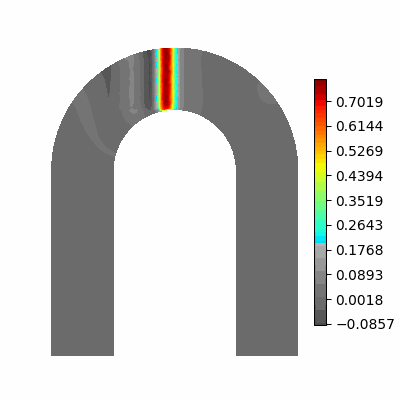

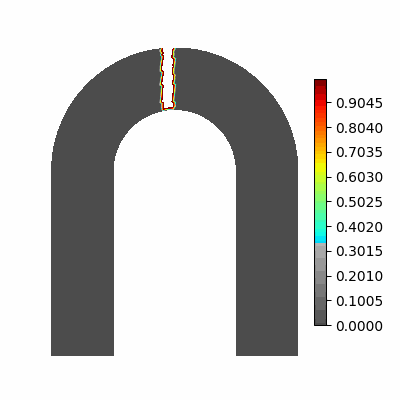

(None, None)

In [ ]:
## Plot showing how results given by the POD-NN and the FOM differ for same assessed simulation
fe.animate(urom2[0], Vh, colorbar = True, cmap = gray_jet), fe.animate(u2[75], Vh, colorbar = True,cmap = gray_jet)

## CONCLUSION

As proceeding with POD-NN, evaluating the latent dynamics of the system using DMD and SINDy, we notice a very bad reconstruction (in the SINDy case it is actually not provided unless for very high threshold values). This can be perceived as a suggestion that this way was not the best to walk on.

Actually, with this *a-posteriori* result, is possible to conclude that the latent dimension identified by the POD is evidently too big.

## DL-ROM IMPLEMENTATION

Moving to the DL-ROM implementation, few steps are required:


1.   Choose the proper activation functions for both encoder and decoder. Here, the usage of an activation function as a sigmoid to move the results back to the dimension $N_h$ seemed to be a reasonable choice as it makes the results ranging in the interval $[0, 1]$ as in this specific case;
2.   Define the latent dimension, that has to satisfy: $$ n \in [p, 2p + 1] \qquad p = p +1 $$
3.   Assemble the encoder and decoder architectures, selecting (with mainly a trial and error approach) the number of neurons to locate in each layer and the number of layers;
4.   Assemble these pieces into the autoencoder and train it.



In [ ]:
# Import the libraries (torch already imported globally by previous loading cells)
from torch.optim import Adam

# Define the activation functions; they are the best functions.
rho_encoder = lambda x: relu(x) - 10*relu(-x)                                   # Leaky ReLU for encoder
rho_decoder = lambda x: relu(x) - 0.1*relu(-x)                                  # Stronger Leaky ReLU for decoder
# rho_sigmoid = lambda x: torch.sigmoid(x)                                      # Introduce this activation function to have the final output in range [0, 1] as the input

# Define the latent space (n = [pt, 2 * pt + 1])
latent = 4

# Define the encoder and the decoder - deep and dense NNs
encoder = Dense(nh, 600, rho_encoder) + Dense(600, latent, rho_encoder)
decoder = Dense(latent, 400, rho_decoder) + Dense(400, 1000, rho_decoder) + Dense(1000, nh, activation = None)

# Assemble the autoencoder
autoencoder = DFNN(encoder + decoder)

# Reshape and pass to the GPU
ufom_dlrom = u.reshape(-1, nh)
autoencoder.cuda()
ufom_dlrom = ufom_dlrom.cuda()
mut = mut.cuda()
u = u.cuda()
l2.cuda() # Assuming l2 is defined later or globally

# Load state dictionary if available, otherwise train
if os.path.exists('/content/autoencoder_state_dict.pth'):
    print("Loading pre-trained 'autoencoder' state dictionary.")
    autoencoder.load_state_dict(torch.load('/content/autoencoder_state_dict.pth'))
    autoencoder.eval() # Set to evaluation mode
else:
    print("No pre-trained 'autoencoder_state_dict.pth' found. Training model...")
    # Start the training: training optimization
    autoencoder.train(ufom_dlrom, ufom_dlrom, ntrain = ntrain, epochs = 100, loss = mse(l2), optim = Adam, lr = 1e-4, batchsize = 64, notation = '%')

    # Refine the results by increasing the learning rate
    autoencoder.train(ufom_dlrom, ufom_dlrom, ntrain = ntrain, epochs = 50, loss = mse(l2), optim = Adam, lr = 1e-5, batchsize = 64, notation = '%')

# Freeze the training
autoencoder.freeze()

Loading pre-trained 'autoencoder' state dictionary.


In [ ]:
## Define u in latent dimension and consider it splitted in both test and training

ulatent = encoder(ufom_dlrom)                                                   # move to the latent space (uh --> un)
ulatent_test = encoder(ufom_dlrom[ntrain:])                                     # u in latent space considering only test data
ulatent_training = encoder(ufom_dlrom[:ntrain])                                 # u in latent space considering only training data
ulatent_test2 = ulatent_test.reshape(numtest, nt, latent)                       # u latent test reshaped as: numtest x numsteptime x latent dimension
ulatent_test.shape, ulatent_training.shape, ulatent_test2.shape

(torch.Size([1025, 4]), torch.Size([3075, 4]), torch.Size([25, 41, 4]))

In [ ]:
## Define the u reconstructed after encoder + decoder
udlrom = decoder(ulatent_test)
udlrom2 = udlrom.reshape(numtest, nt, nh)
u.shape, udlrom.shape, udlrom2.shape

(torch.Size([4100, 6636]),
 torch.Size([1025, 6636]),
 torch.Size([25, 41, 6636]))

In [ ]:
## Maximum and minimum values of the reconstructed solution after autoencoder
# Recalling that the boundaries of such solution are: [0, 1]
udlrom2.max(), udlrom.min()

(tensor(1.1771, device='cuda:0'), tensor(-0.1920, device='cuda:0'))

### Design $\Phi(\mu)$

Once the autoencoder has been assembled, to enter in the latent space with a new parameter the analogous technique as the one used with POD-NN is implemented. Specifically, a Neural Network $\Phi(\mu)$ is created: it takes in input the parameters' vector and provides the solution in latent space, that has been obtained with the encoder-decoder combination.

Notice that, being time present in this model, it is included in the parameters vector. This choice is a bit outside the meaning of the problem, as time is reduced to being simply a parameter and not something related somehow to the physical evolution of the damage.

In [ ]:
mut.shape, ulatent_test.shape, ulatent.shape

(torch.Size([4100, 4]), torch.Size([1025, 4]), torch.Size([4100, 4]))

In [ ]:
## Design the NN to learn the map mut --> latent space

phi = DFNN(Dense(pt, 50, gelu) + Dense(50, 50, gelu) + Dense(50, latent, None))

phi.He()
phi.to(dv) # Assuming dv is imported and functional

# Load state dictionary if available, otherwise train
if os.path.exists('/content/dlrom_phi_state_dict.pth'):
     print("Loading pre-trained 'dlrom_phi' state dictionary.")
     phi.load_state_dict(torch.load('/content/dlrom_phi_state_dict.pth'))
     phi.eval() # Set to evaluation mode
else:
    print("No pre-trained 'dlrom_phi_state_dict.pth' found. Training model...")
    phi.train(mut, ulatent, loss = mse(euclidean), epochs = 50, ntrain = ntrain)

Loading pre-trained 'dlrom_phi' state dictionary.


### DL-ROM error

The average relative error with $L^2$ norm is computed for the DL-ROM solution, using the same error function of the POD-NN.

Again, the result is quite good, as it is below the asked threshold of $10 \%%$. The problem comes with the second error, that results as being (a little) above the required threshold. This is due to a compromise that was necessary in order to find then, in the SINDy implementation, a reasonable solution for the analyzed case.

In [ ]:
## L2 relative error using encoder + decoder

print("DL-ROM average relative error with L2 norm (the one requested): %s" % num2p(error(ufom_dlrom[ntrain:], udlrom)))

# ufom_dlrom[ntrain:] solution by fom over test
# udlrom solution rom over test

DL-ROM average relative error with L2 norm (the one requested): 5.13%


In [ ]:
## L2 relative error using phi + decoder

dlrom = lambda mt: decoder(phi(mt))
print("DL-ROM average relative error with L2 norm (the one requested): %s" % num2p(error(u[ntrain:], dlrom(mut[ntrain:]))))

# this error takes into account the phi transformation
# NOT consider the encoder contribution

DL-ROM average relative error with L2 norm (the one requested): 13.58%


# **2) EFFICIENCY**

The efficiency analysis is here exploited - for both the DL-ROM and POD-NN implementation.

As a preliminary stage is necessary to assemble the vector $\mu$ which includes both the parameters and the time, for a unique trajectory. Indeed, the shape of the final vector is: $ n_t \times p$, where $ p = p + 1 $.

Then, the counter is started as a solution is computed using, separately, both the DL-ROM and POD-NN. For both the results the solution comes as (almost) time effortless, especially if compared with the one of the FOM.

In [ ]:
## Define basic data to compute efficiency
# FOM time to compute one trajectory
dtFOM = 19.33

# Computational time
from time import perf_counter
mu0 = dv.tensor(np.random.rand(p))
t = dv.tensor(np.linspace(0, T, nt))

mu0t = dv.zeros(1, nt, p+1)                                                     # create null tensor of desidered shape  (100 x 41 x 4)
for i in range(1):                                                              # add values to mut
  mu0t[i, :, :p] = mu0[i]
  mu0t[i, :, p] = t
mu0t = mu0t.reshape(-1, p+1)

## DL-ROM EFFICIENCY

In [ ]:
## DL-ROM Efficiency

t0_dlrom = perf_counter()
uDLROM = dlrom(mu0t)
t1_dlrom = perf_counter()
dtROM = t1_dlrom-t0_dlrom
print("DL-ROM simulation time: %.5fs." % (dtROM))
print(f"The difference in computational time is: {dtFOM - dtROM:.5f} s")
print("\n>> Boost: x%d." % (dtFOM//dtROM))

DL-ROM simulation time: 0.00180s.
The difference in computational time is: 19.32820 s

>> Boost: x10712.


## POD-NN EFFICIENCY

In [ ]:
## Evaluate time of computation
t0 = perf_counter()
utime = phi_PODNN(mu0t) @ Vn.T
t1 = perf_counter()
dtPODNN = t1-t0
print(f"The computational time of the POD-NN architecture is: {dtPODNN:.5f} s")
print(f"The difference in computational time is: {dtFOM - dtPODNN:.5f} s")
print("\n>> Boost: x%d." % (dtFOM//dtPODNN))

The computational time of the POD-NN architecture is: 0.00244 s
The difference in computational time is: 19.32756 s

>> Boost: x7910.


# **3) PARAMETERS ESTIMATION FROM SENSOR DATA**

The third stage consists in evaluating the value of the parameters $ D, r, \delta $ so that the error between the measurements of damage in a point and the ones estimated, in the same location, by the DL-ROM and POD-NN, is minimized.

The procedure is the following:
1.   Define the objective function by exploiting the auxiliary function *evaluate*;
2.   Minimize it;
3. Extract the values of  $ D, r, \delta $ according to their relationship with the vector $\mu$ (as defined above);
4.   Plot the DL-ROM results compared with those given by FOM.

### Auxiliary tools

In [ ]:
# Auxiliary functions for pointwise evaluations (needed for Task (iii))
from dlroms.minns import Evaluate
x0 = np.array([[0.5, 3]])                                                       # damage measurement point
evaluate = Evaluate(mesh, Vh, x0)                                               # extraction of a specific point from the Vh mesh - indeed, dimension will no more consider nh = 6636
evaluate.to(dv)

# Usage example
uLoc = u2[0]                                                                    # u2 has shape ndata x nt x nh - here selecting the first trajectory
damage_atx0 = evaluate(uLoc)                                                    # returns a tensor of shape (Nt, 1), corresponding to the values of u0 at x0 over time
damage_atx0.shape

torch.Size([41, 1])

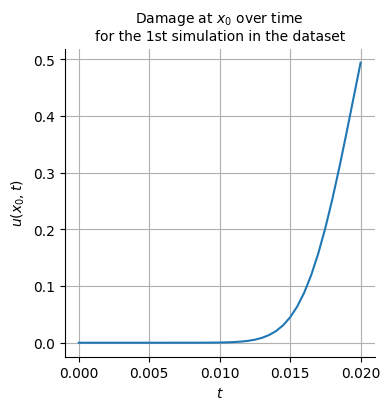

In [ ]:
nt = len(uLoc)
T = (nt-1)*5e-4                                                                 # T = 0.02 (given by text)

time_grid = np.linspace(0, T, nt)

plt.figure(figsize = (4, 4))
plt.plot(time_grid, damage_atx0.cpu().numpy())
plt.title("Damage at $x_0$ over time\nfor the 1st simulation in the dataset", fontsize = 10)
plt.xlabel("$t$")
plt.ylabel("$u(x_0,t)$")
plt.grid(True)
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.show()
None

In [ ]:
# Measurements available (corresponding to "evaluate(u)" for some unknown u!)
# those called in the formula m_j
gdown.download(id = "16htWP91l5tpgK3ZYqjK-GHvVpW7lr2a5", quiet = False, output = "damage_measurements.npy")
clc()

damage_measurements = np.load("damage_measurements.npy")
damage_measurements.shape

(41, 1)

### Optimized ${D}, \  {r}, \  δ$ - DL-ROM

In [ ]:
# DL ROM
## Define the objective function to be minimized

def objective(mu_sens, nt, damage_measurements, decoder, phi, Vn, evaluate):
  t = dv.tensor(np.linspace(0, T, nt))
  mut_sens = dv.zeros(nt, p+1)                                                  # create null tensor of desidered shape  (41 x 4)
  mut_sens[:, :p] = dv.tensor(mu_sens)                                          # add values to mut_sens
  mut_sens[:, p] = t                                                            # add t to mut_sens
  mut_sens = mut_sens.reshape(-1, p+1)
  uROM = decoder(phi(mut_sens))                                                 # uROM solution for mut parameters and time
  uROM_sens = evaluate(uROM).detach().cpu().numpy().flatten()                   # uROM solution in the position of the sensor
  mse = np.square(damage_measurements.flatten() - uROM_sens).mean()
  return mse

## Minimization
from scipy.optimize import differential_evolution
res = differential_evolution(objective, args=(nt, damage_measurements, decoder, phi, Vn, evaluate), bounds=[(0, 1), (0, 1), (0, 1)])

## Optimized mu vector
mu_opt_dlrom = res.x
print(f"The optimized vector mu is: ({mu_opt_dlrom[0]:.2f}, {mu_opt_dlrom[1]:.2f}, {mu_opt_dlrom[2]:.2f})")

## Define the parameters after optimization
D_dlrom = 10**(mu_opt_dlrom[0])
R_dlrom = 10**(mu_opt_dlrom[1] + 2)
delta_dlrom = mu_opt_dlrom[2] + 1

print(f"\nThe parameters obtained with MSE minimization are: ")
print(f"D = {D_dlrom:.2f}, r = {R_dlrom:.2f}, δ = {delta_dlrom:.2f}")

The optimized vector mu is: (0.55, 0.81, 0.69)

The parameters obtained with MSE minimization are: 
D = 3.54, r = 642.29, δ = 1.69


### Optimized ${D}, \  {r}, \  δ$ - POD-NN

In [ ]:
# PODNN
## Define the objective function to be minimized

def objective(mu_sens, nt, damage_measurements, phi_PODNN, Vn, evaluate):
  t = dv.tensor(np.linspace(0, T, nt))
  mut_sens = dv.zeros(nt, p+1)                                                  # create null tensor of desidered shape  (41 x 4)
  mut_sens[:, :p] = dv.tensor(mu_sens)                                          # add values to mut_sens
  mut_sens[:, p] = t                                                            # add t to mut_sens
  mut_sens = mut_sens.reshape(-1, p+1)
  uROM = phi_PODNN(mut_sens) @ Vn.T                                             # uROM solution for mut parameters and time
  uROM_sens = evaluate(uROM).detach().cpu().numpy().flatten()                   # uROM solution in the position of the sensor
  mse = np.square(damage_measurements.flatten() - uROM_sens).mean()
  return mse

## Minimization
from scipy.optimize import  differential_evolution
res = differential_evolution(objective, args=(nt, damage_measurements, phi_PODNN, Vn, evaluate), bounds=[(0, 1), (0, 1), (0, 1)])

## Optimized mu vector
mu_opt_podnn = res.x
print(f"The optimized vector mu is: ({mu_opt_podnn[0]:.2f}, {mu_opt_podnn[1]:.2f}, {mu_opt_podnn[2]:.2f})")

## Define the parameters after optimization
D_podnn = 10**(mu_opt_podnn[0])
R_podnn = 10**(mu_opt_podnn[1] + 2)
delta_podnn = mu_opt_podnn[2] + 1

print(f"\nThe parameters obtained with MSE minimization (PODNN) are: ")
print(f"D = {D_podnn:.2f}, r = {R_podnn:.2f}, δ = {delta_podnn:.2f}")


The optimized vector mu is: (0.38, 0.89, 0.85)

The parameters obtained with MSE minimization (PODNN) are: 
D = 2.41, r = 782.70, δ = 1.85


### PLOT with DL-ROM solution

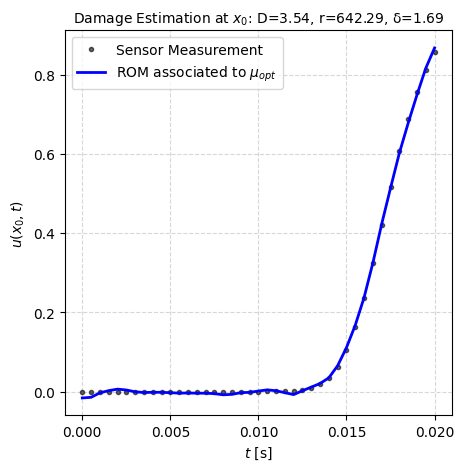

In [ ]:
# Define the mu that we found => analyzing the evolution of mu along each time step

mu_final = torch.zeros((nt, p + 1)).to(dv.device)
mu_final[:, :p] = torch.tensor(mu_opt_dlrom, dtype=torch.float32).to(dv.device)
mu_final[:, p] = torch.linspace(0, T, nt).to(dv.device)

# Define the value of uROM associated to the mu_opt we found
uROM_final = decoder(phi(mu_final))
damage_est_atx0 = evaluate(uROM_final).detach().cpu().numpy()

# Create the plot
plt.figure(figsize = (5, 5))
damage_measurements = damage_measurements.squeeze()
damage_est_atx0 = damage_est_atx0.squeeze()
plt.plot(time_grid, damage_measurements, 'ko', markersize=3, label="Sensor Measurement", alpha=0.6)              # Plot 1 => What the sensor detects
plt.plot(time_grid, damage_est_atx0, 'b-', linewidth=2, label=r"ROM associated to $\mu_{opt}$")                   # Plot 2 => What my solution found

# Custom the plot
plt.title(f"Damage Estimation at $x_0$: D={D_dlrom:.2f}, r={R_dlrom:.2f}, δ={delta_dlrom:.2f}", fontsize = 10)
plt.xlabel("$t$ [s]")
plt.ylabel("$u(x_0,t)$")
plt.xticks(torch.linspace(0, T, 5).numpy())
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# **4) DMD and SINDy**

## **DMD with PODNN**

The Dynamic Mode Decomposition is one of the two strategies that can be used to explore the dynamics of a system by looking at its latent behaviour. Differently than Sparse Identification of Non-Linear Dynamics (SINDy), the approached used by DMD is linear - and it is a first suggestion of why it may not be the best in our case, looking at the second order quasi-static parabolic PDE.  

The steps are divided as follows:
1.   Creation of a PODNNsolver function that allows to compute the result given by the POD-NN reconstructed $N_h$;
2.   Define $u_{now}$ and $u_{next}$ from the $u_{train}$ vector, considering respectively all the time instants except the last one, and all the time instants except the first one, so that they will appear as shifted;
3.   Compute the SVD of the $u_{now}$ vector, and use it to build the matrix $S$;
4. Extract the eigenvectors and eigenvalues of $S$ to define the DMD solver function to make predictions;
5.   Assemble the vector containing for the first interval ($[0, 0.02] s$) the values obtained with POD-NN and for the other interval ($[0.02, 0.04] s$);
6. Use the prediction vector and the evaluate function to predict the damage in the location $x^{*} = [3.5, 2]$ at $t^* = 0.04s$.

In [ ]:
def PODNNsolver(mu_new, time_grid):
  mutDMD = dv.zeros(len(time_grid), p+1)
  mutDMD[:, p] = dv.tensor(time_grid)
  mutDMD[:, :p] = dv.tensor(mu_new)
  return (phi_PODNN(mutDMD) @ Vn.T).cpu().numpy()

utrain_podnn = PODNNsolver(mu_opt_podnn, time_grid = np.linspace(0, T, nt))                 # u reconstructed by PODNN considering optimized parameters and t = [0, 0.02]
utrain_podnn.shape                                                                          # nt x nh

(41, 6636)

In [ ]:
unow_podnn = utrain_podnn.T[:, :-1]                                             # all except the last one
unext_podnn = utrain_podnn.T[:, 1:]                                             # all except the first
unow_podnn.shape
# plotting them, notice that (of course!) the first value of unext = second value of unow

(6636, 40)

### SVD

In [ ]:
from scipy.linalg import svd
from scipy.linalg import eig

# Perform SVD
U, sigma, Vt = svd(unow_podnn, full_matrices = False)

# Selecting all contributions (i.e. n = 50)
S = U.T @ unext_podnn @ Vt.T @ np.diag(1.0/sigma)
#U.shape, sigma.shape, unext_podnn.shape, Vt.shape, S.shape

# Eigenvalues and eigenvectors
eigenvalues, rotated_eigenvectors = eig(S)
eigenvectors = U @ rotated_eigenvectors
eigenvalues = eigenvalues

#eigenvectors, eigenvalues

### DMD

In [ ]:
## DMD evolution scheme
def DMDevolve(u0, steps):
   cDMD = np.linalg.lstsq(eigenvectors, u0)[0]
   return np.stack([np.real(eigenvectors @ (eigenvalues**k*cDMD)) for k in range(steps)], axis = 1).T

uDMD = DMDevolve(utrain_podnn[-1], nt)

In [ ]:
## Assemble the predicted u values exploiting DMD
upred_podnn = np.zeros((nt*2, nh))
upred_podnn[:nt] = utrain_podnn
upred_podnn[nt:] = uDMD

utrain_podnn.shape, uDMD.shape, upred_podnn.shape
# utrain_podnn, uDMD, upred_podnn

((41, 6636), (41, 6636), (82, 6636))

### DAMAGE AT $x^{*}$

In [ ]:
## Estimate if at t* = 0.04s the damage has reached x* = [3.5, 2]

# Define the interest point and time instant
t_star = 2*T
x_star = np.array([[3.5, 2]])

# Consider the correspondent x_star value in the mesh location --> exploit "Evaluate" function
x_star_mesh = Evaluate(mesh, Vh, x_star)
x_star_mesh.to(dv)

# Damage in x* at time instant t*
upred_podnn = dv.tensor(upred_podnn)                                            # transform upred into tensor
u_star = upred_podnn                                                            # consider all the values
damage_x_star = x_star_mesh(u_star)                                             # value of u at x_star for ALL the time instants (up to 82)
damage_x_star.shape                                                             # expect 82x1 as 82=nt*2, 1=only one point of the mesh is considered

torch.Size([82, 1])

In [ ]:
print(f'The value of u at x* = {x_star} and t* = {t_star} is: ')
print(f'u = {float(damage_x_star[81]):.5f}')

The value of u at x* = [[3.5 2. ]] and t* = 0.04 is: 
u = 493.41907


The DMD solution is, if needed, another argumentation that leverages the fact that POD-NN is not good.

## **SINDy**

Here the SINDy is implemented, for both DL-ROM and POD-NN. After having implemented a DLROMsolver function, the imported SINDy model has been created. Then, the dynamics explored by SINDy in latent space has been moved to the $N_h$ dimension and evaluated the predicted damage value at the interest point. Here, the main effort was related to the identification of the proper functions and values of threshold and alpha.

The behaviour seen in the DL-ROM graph is growing as the fatigue is experienced by the U-bolt, but it is not bounded in the range $[0, 1]$ as by definition of $u_h$. This is so a problem of inconsistency with the results, that maybe could be fixed by a more accurate refinment of the functions used.

Anyway, the DL-ROM result is quite acceptable and reasonable, even tough the bounds are exceeded. Differently the one of the POD-NN is something non feasible (the code runs without providing a solution).

### SINDy DL-ROM

In [ ]:
# Import libraries
from IPython.display import clear_output as clc
try:
  from pysindy import SINDy, CustomLibrary, STLSQ
except:
  !pip install git+https://github.com/dynamicslab/pysindy.git
  clc()
  from pysindy import SINDy, CustomLibrary, STLSQ

In [ ]:
## Define the function that allows to analyze the dynamics of the system starting from a bunch of new parameters

def DLROMsolver(mu_new, time_grid):
  mutSIND = dv.zeros(len(time_grid), p+1)
  mutSIND[:, p] = dv.tensor(time_grid)
  mutSIND[:, :p] = dv.tensor(mu_new)
  return ((phi(mutSIND))).detach().cpu().numpy()

# considering the DLROM as something that only moves things to the latent space
# define ztrain as the latent version
ztrain = DLROMsolver(mu_new=mu_opt_dlrom, time_grid = np.linspace(0, T, nt))
ztrain.shape

(41, 4)

In [ ]:
from pysindy.feature_library import PolynomialLibrary

dim = latent
functions = [lambda z: z, lambda z: z**2, lambda z,x: z*x, lambda z: 1/(1+np.exp(-z))]
model =  SINDy(feature_library = CustomLibrary(library_functions=functions, include_bias = True), optimizer = STLSQ(threshold=15, alpha=5))

dt = float(t[1] - t[0])                                                         # convert to float

z_train_sindy = dv.tensor(ztrain).detach().cpu().numpy()                        # consider the behavior of the latent space
z_state = z_train_sindy[1:-2, :]
z_dot_sindy = (z_train_sindy[2:-1, :]-z_train_sindy[0:-3, :])/(2.0*dt)

model.fit(z_state, x_dot = z_dot_sindy, t = dt, feature_names = ["z%d" % i for i in range(1, dim+1)])
print('The latent dynamics is described by the following state: ')
model.print()

The latent dynamics is described by the following state: 
(z1)' =  64.181 f0(z4) +  38.772 f1(z2) +  28.132 f1(z4) + -57.186 f2(z2,z4) + -29.441 f2(z3,z4)
(z2)' = -16.219 f1(z2) +  18.111 f2(z2,z4)
(z3)' = -77.282 f0(z4) +  64.167 f1(z2) +  38.724 f1(z4) + -38.353 f2(z2,z3) + -70.633 f2(z2,z4) + -23.697 f2(z3,z4)
(z4)' =  663.498 f0(z4) + -78.173 f1(z2) + -73.188 f1(z4) +  69.627 f2(z2,z3) +  94.174 f2(z2,z4)


In [ ]:
print(z_train_sindy.device)

cpu


In [ ]:
## Define the interest point and time instant
t_star = 2*T
x_star = np.array([[3.5, 2]])

In [ ]:
def sindy_evolve(z0, tempo):
  return model.simulate(z0, t = t2)

z0 = z_train_sindy[-1] #.cpu()
t2 = np.linspace(0, t_star - T, nt)                                             # take last trained data for future analysis

zsindy = sindy_evolve(z0, t2)
zsindy = dv.tensor(zsindy)
z_train_sindy = dv.tensor(z_train_sindy)

## Define the dynamics in latent space as train + sindy
zpred = np.zeros((2*nt, latent))
zpred[:nt] = ((z_train_sindy).detach().cpu().numpy())
zpred[nt:] = ((zsindy).detach().cpu().numpy())

zsindy.shape, z_train_sindy.shape, zpred.shape

(torch.Size([41, 4]), torch.Size([41, 4]), (82, 4))

In [ ]:
## Reconstruct the dynamics in space nh
upred_dlrom = np.zeros((2*nt, nh))

upred_dlrom[:nt] = (decoder(z_train_sindy).detach().cpu().numpy())
upred_dlrom[nt:] = (decoder(zsindy).detach().cpu().numpy())
upred_dlrom[:nt].shape, upred_dlrom[nt:].shape, upred_dlrom.shape

((41, 6636), (41, 6636), (82, 6636))

In [ ]:
## Evaluate the damage at x*, t*
x_star = np.array([[3.5, 2]])
evaluate_star = Evaluate(mesh, Vh, x_star)
upred_sindy_dv = dv.tensor(upred_dlrom).cpu()

damage_at_x_star = evaluate_star(upred_sindy_dv)

damage_final = float(damage_at_x_star[-1])
print(f'The damage in {x_star} at instant t = {t_star} is: {damage_final:5f}')   # all values should be in range 0 - 1

The damage in [[3.5 2. ]] at instant t = 0.04 is: 1.118809


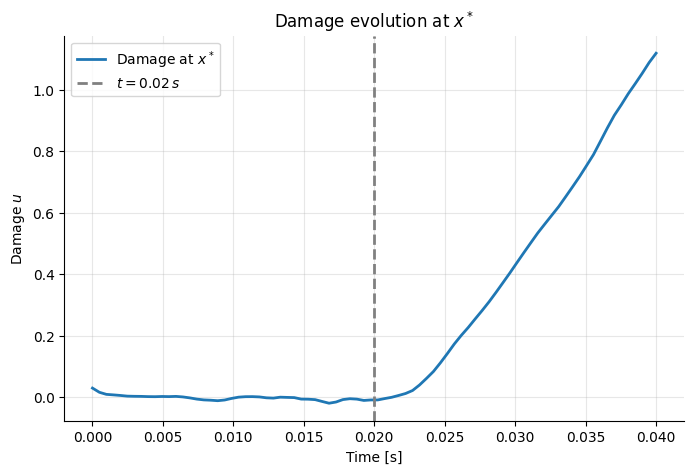

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Time
timetime = np.linspace(0, 2*T, 2*nt)
t = timetime.flatten()

# Plot over the whole interval [0, 0.04]s
plt.figure(figsize=(8, 5))
damage = damage_at_x_star.flatten()

plt.plot(t, damage, linewidth=2, label='Damage at $x^*$')
plt.axvline(x=0.02, color='gray', linestyle='--', linewidth=2,
            label=r'$t = 0.02\,s$')
plt.xlabel('Time [s]')
plt.ylabel('Damage $u$')
plt.title('Damage evolution at $x^*$')
plt.grid(True, alpha=0.3)
plt.legend()
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.show()


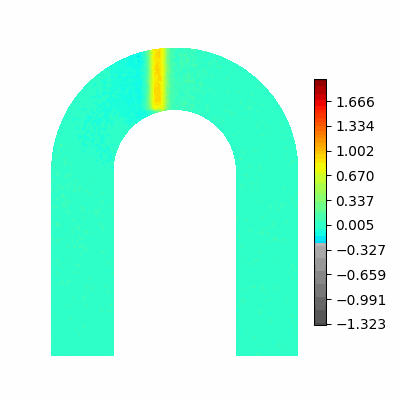

In [ ]:
fe.animate(upred_sindy_dv, Vh, colorbar = True, cmap = gray_jet)

In [ ]:
## Relevance of damage on x*
damage = float(damage_final)
ths = 0.5                                                                       # as the damage value can range between 0 - 1, assume 0.5 to be the point of division between relvant/non relevant damage
damage, damage_final
if damage <= ths:
   print(f'Damage is not relevant. (= {damage:.3f})')
else:
     print(f'Damage is relevant. (= {damage:.3f})')

Damage is relevant. (= 1.119)


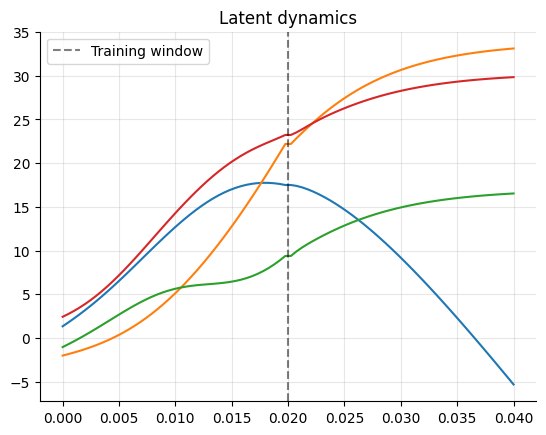

In [ ]:
## Plot the latent dynamics

plt.plot(timetime, zpred)
plt.title("Latent dynamics")
xylim = plt.gca().axis()
plt.axvline(x=T, color='k', linestyle='--', alpha=0.5, label='Training window')

plt.grid(True, alpha=0.3)
plt.legend()
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.axis(xylim)
plt.show()


### SINDy PODNN

Implementing the SINDy with POD-NN, the result will not be provided as the code will not stop running.

In [ ]:
# from pysindy.feature_library import PolynomialLibrary

# dim = n                                                                         # dimension of latent space (set n = 5! to have a solution, also in POD basis)
# library = PolynomialLibrary(degree=2, include_interaction=False)
# model =  SINDy(feature_library = library, optimizer = STLSQ(threshold=25, alpha=6, max_iter=20))    # coefficients < threshold  are set = 0

# dt = float(t[1] - t[0])                                                         # convert to float

# zstate = utrain[1:-1]
# zdot = (utrain[2:]-utrain[:-2])/(2.0*dt)                                        # z(k+1) - z(k) / 2dt -- derivative
# #zstate.shape, zdot.shape

# model.fit(zstate, x_dot = zdot, t = dt, feature_names = ["z%d" % i for i in range(1, dim+1)])    # generate the state equations (expect 50 eq.)
# model.print()

In [ ]:
# def sindy_evolve(z0, tempo):
#   return model.simulate(z0, t = tempo)

# z0 = ztrain[-1]
# tempo = np.linspace(0, T2 - T, nt)                                                               # take last trained data for future analysis
# zsindy = sindy_evolve(z0, tempo)
# zsindy.shape, ztrain.shape

In [ ]:
# zpred = np.concatenate((ztrain, zsindy), axis =0)
# # plt.plot(np.linspace(n-dt*len(zpred), n, len(zpred)), zpred)
# # plt.title("Latent dynamics")
# # xylim = plt.gca().axis()
# # plt.plot(T2, [xylim[2], xylim[3]], '--k', alpha = 0.5, label = 'Training window')
# # plt.legend()
# # plt.axis(xylim)
# # None
# zpred.shape

In [ ]:
# upred = np.zeros((2*nt, nh))
# # move zpred to upred dimension
# VnT = Vn.detach().cpu().numpy()
# # upred_extr = zpred @ VnT.T
# upred[:nt] = ztrain @ VnT.T
# upred[nt:] = zsindy @ VnT.T
# upred[:nt], upred[nt:], upred.shape

In [ ]:
# evaluate_star = Evaluate(mesh, Vh, xfut)
# upred_sindy_dv = dv.tensor(upred)

# damage_at_x_star = evaluate_star(upred_sindy_dv)
# xfut = np.array([[3.5, 2]])

# damage_final = damage_at_x_star[-1]
# print(damage_final)

**____________________________________________________________________________________________________________________________**


# **SAVE THE DATA (ignore)**

### Saving Data

First, let's save the numerical data.

In [ ]:
# import numpy as np
# import torch

# # Ensure tensors are on CPU and converted to numpy for saving with np.savez
# np.savez('saved_data.npz',mu=mu.cpu().numpy(),u=u.cpu().numpy(),mut=mut.cpu().numpy(), zsindy=zsindy.cpu())
# print("Numerical data saved to 'saved_data.npz'")

Next, save the state dictionaries of the trained neural network models. This allows for recreating the models with their learned weights later.

In [ ]:
# torch.save(phi_PODNN.state_dict(), 'phi_PODNN_state_dict.pth')
# print("phi_PODNN state dictionary saved to 'phi_PODNN_state_dict.pth'")

# torch.save(autoencoder.state_dict(), 'autoencoder_state_dict.pth')
# print("Autoencoder state dictionary saved to 'autoencoder_state_dict.pth'")

# torch.save(phi.state_dict(), 'dlrom_phi_state_dict.pth')
# print("DL-ROM phi state dictionary saved to 'dlrom_phi_state_dict.pth'")

### Save files to Google Drive

In [ ]:
# from google.colab import drive
# import shutil
# import os

# drive.mount('/content/drive')

# source_files = [
#     'u-bolt.npz',
#     'damage_measurements.npy',
#     'phi_PODNN_state_dict.pth',
#     'autoencoder_state_dict.pth',
#     'dlrom_phi_state_dict.pth',
#     'saved_data.npz'
# ]

# destination_folder = '/content/drive/Shareddrives/ASSIGNMENT'

# # Create the destination folder if it doesn't exist
# os.makedirs(destination_folder, exist_ok=True)

# for file_name in source_files:
#     source_path = os.path.join('/content', file_name)
#     destination_path = os.path.join(destination_folder, file_name)
#     if os.path.exists(source_path):
#         shutil.copy(source_path, destination_path)
#         print(f"Copied '{file_name}' to '{destination_folder}'")
#     else:
#         print(f"Warning: '{file_name}' not found at '{source_path}'")

# print("All specified files have been copied to Google Drive.")

In [ ]:
# # Example of how to load them back
# from google.colab import drive
# import shutil
# import os

# drive.mount('/content/drive')

# source_folder = '/content/drive/MyDrive/Colab_Saved_Files' # Same path as where you saved them
# destination_folder = '/content' # Copy back to /content

# files_to_load = [
#     'u-bolt.npz',
#     'damage_measurements.npy',
#     'phi_PODNN_state_dict.pth',
#     'autoencoder_state_dict.pth',
#     'dlrom_phi_state_dict.pth',
#     'saved_data.npz'
# ]

# for file_name in files_to_load:
#     source_path = os.path.join(source_folder, file_name)
#     destination_path = os.path.join(destination_folder, file_name)
#     if os.path.exists(source_path):
#         shutil.copy(source_path, destination_path)
#         print(f"Copied '{file_name}' from Drive to '{destination_folder}'")
#     else:
#         print(f"Warning: '{file_name}' not found in Drive at '{source_folder}'")

# print("All specified files have been loaded from Google Drive.")

# After loading, you would then load the data into your variables/models
# Example for numerical data:
# loaded_data = np.load('/content/saved_data.npz')
# mu = torch.tensor(loaded_data['mu'])
# u = torch.tensor(loaded_data['u'])
# mut = torch.tensor(loaded_data['mut'])
# zsindy = torch.tensor(loaded_data['zsindy'])

# Example for models (assuming the models are defined in the notebook already)
# phi_PODNN.load_state_dict(torch.load('/content/phi_PODNN_state_dict.pth'))
# phi_PODNN.eval()
# autoencoder.load_state_dict(torch.load('/content/autoencoder_state_dict.pth'))
# autoencoder.eval()
# phi.load_state_dict(torch.load('/content/dlrom_phi_state_dict.pth'))
# phi.eval()